In [11]:
#Import functions in library
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate, stats
from mp3lib import (sample_mean_cov, is_valid_covariance, gaussian_pdf, whitening_matrix, lmmse_weights)

#Use SEED number
SEED = 1506714529 # drawn 2026-11-09, do not change
rng = np.random.default_rng(SEED)

#Generate one independent random-number generator for each step
rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]
rng_step4 = rng.spawn(1)[0]
rng_step5 = rng.spawn(1)[0]
rng_step6 = rng.spawn(1)[0]
rng_step7 = rng.spawn(1)[0]
rng_step8 = rng.spawn(1)[0]

np.set_printoptions(precision=6, suppress=True)
PROJECT_START = time.perf_counter()

Step 1

Get the mechanics of joint, marginal, and conditional densities working
with (X, Y) Joint density 𝑓𝑋𝑌 (𝑥, 𝑦) = 𝑥 + 𝑦, 0 ≤ 𝑥 ≤ 1, 0 ≤ 𝑦 ≤ 1

Valid Densities must be nonnegative and integrate to 1

x + y ≥ 0 $\int_{0}^{1}\int_{0}^{1} (x + y) \,dy\,dx$ 

= $\int_{0}^{1} (x + {[(1^2)/2]-[(0^2)/2]}) \,dx$ 

= $\int_{0}^{1} (x + 1/2) \,dx$ 

= [(1^2)/2] + (1/2)1 - {[(0^2)/2] + (1/2)0}

= 1/2 + 1/2 = 1

Thus, the density is valid because it is nonnegative and it integrates to 1.



In [12]:
#Confirm the Density is valid numerically using a 2D quadrature
def joint_pdf_xy(x, y):
    if 0 <= x <= 1 and 0 <= y <= 1:
        return x + y
    return 0.0
joint_integral, joint_quad_error = integrate.dblquad(lambda y, x: x + y, 0, 1, lambda x: 0, lambda x: 1)
print(f"Joint-density integral = {joint_integral:.10f}")
print(f"Quadrature estimated absolute error = {joint_quad_error:.3e}")

Joint-density integral = 1.0000000000
Quadrature estimated absolute error = 1.663e-14


Derive both marginals

$ 𝑓_𝑋(𝑥) $ = $\int_{-∞}^{∞} 𝑓_{𝑋𝑌} (𝑥, 𝑦) \,dy$

$ 𝑓_𝑋(𝑥) $ = $\int_{0}^{1} (x + y) \,dy$

= [xy + (y^2)/2] y = 1 and 0

= [x(1) + (1^2)/2] - [x(0) + (0^2)/2]

$ 𝑓_𝑋(𝑥) $ = {x + 1/2, 0 ≤ 𝑥 ≤ 1
        
         0, otherwise}
$ 𝑓_𝑋(.3) $ = .3 + .5 = .8 

<br>
<br>
<br>
$ 𝑓_Y(y) $ = $\int_{0}^{1} (x + y) \,dx$

= [xy + (x^2)/2] x = 1 and 0

= [y(1) + (1^2)/2] - [y(0) + (0^2)/2]

$ 𝑓_Y(y) $ = {y + 1/2, 0 ≤ y ≤ 1

         0, otherwise}

Thus, outside [0,1] both marginal densities are 0

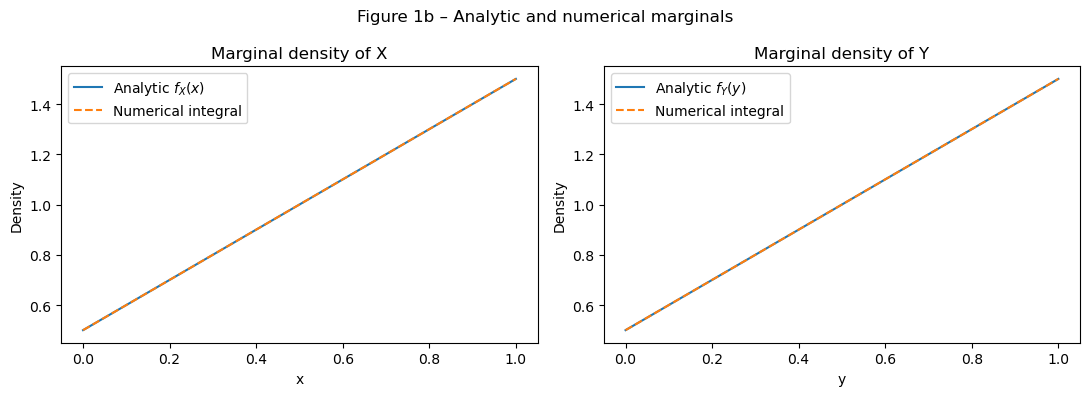

Maximum marginal-grid error: 8.881784197001252e-16


In [13]:
#Confirm numerically by integrating joint density 
grid = np.linspace(0, 1, 501)
Xg, Yg = np.meshgrid(grid, grid, indexing="xy")
Zg = Xg + Yg
fx_analytic = grid + 0.5
fy_analytic = grid + 0.5
#Integrate the joint density along the other coordinate
fx_numeric = np.trapezoid(Zg, grid, axis=0)   #integrate over y, retain x
fy_numeric = np.trapezoid(Zg, grid, axis=1)   #integrate over x, retain y
#Plot data
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(grid, fx_analytic, label="Analytic $f_X(x)$")
ax[0].plot(grid, fx_numeric, "--", label="Numerical integral")
ax[0].set(title="Marginal density of X", xlabel="x", ylabel="Density")
ax[0].legend()
ax[1].plot(grid, fy_analytic, label="Analytic $f_Y(y)$")
ax[1].plot(grid, fy_numeric, "--", label="Numerical integral")
ax[1].set(title="Marginal density of Y", xlabel="y", ylabel="Density")
ax[1].legend()
fig.suptitle("Figure 1b – Analytic and numerical marginals")
plt.tight_layout()
plt.show()
print("Maximum marginal-grid error:",
      max(np.max(np.abs(fx_numeric-fx_analytic)),
          np.max(np.abs(fy_numeric-fy_analytic))))

After integrating the joint probability denisty function 𝑓𝑋𝑌 (𝑥, 𝑦) = 𝑥 + 𝑦 over the variable that wasn't considered we obtained x + 1/2 for 0 ≤ 𝑥 ≤ 1 and y + 1/2 for 0 ≤ y ≤ 1 with 0 otherwise for both. Therefore, when x = .3, then fX(.3) = .3 + .5 = .8. Thus, one may see that both marginal densities are defined over the interval [0,1] with 0 elsewhere. To confirm the result, numerical integration was used and as we can see by the graphs that both curves closely overlap, which proves that the integration agrees with the derivations. Therefore, after calculating max marginal error, we obtained a 8.88 x 10^-16, which is small enough to demonstrate a success in our data and prove that both results are similar. After all, the small error was due to the finite spacing in the graph and the numerical integration through trapezoid. Since both graphs have an increasing linear shape, we can deduce that higher X and Y values have a higher marginal probablity density than lower values. For instance, when X is 1/2, then the marginal density is 1. Although the marginal densities describe each variable individually, the joint density describes the relationship between both variables.

Derive conditional density of Y given X = x

$\ f_{Y|X}(y|x) = \frac{f_{XY}(x,y)}{f_X(x)} = \frac{x+y}{x+1/2},\quad0\leq y\leq1 \$

At x = .3 

$\ f_{Y|X}(y|0.3) = \frac{0.3+y}{0.8},\quad0\leq y\leq1 \$

$\ \int_0^1\frac{0.3+y}{0.8}dy = \frac{0.3+0.5}{0.8} = 1 \$

It integrates to 1 because it is a conditional density.

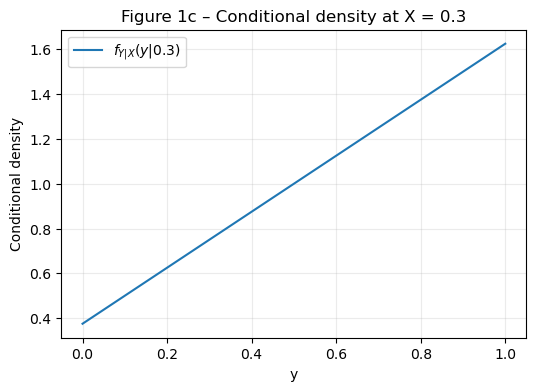

Conditional density integral = 1.00000000


In [14]:
#Plot of conditional density at x = .3
x0 = 0.3
conditional = (x0 + grid) / (x0 + 0.5)
conditional_integral = np.trapezoid(conditional, grid)
plt.figure(figsize=(6, 4))
plt.plot(grid, conditional, label=r"$f_{Y|X}(y|0.3)$")
plt.xlabel("y")
plt.ylabel("Conditional density")
plt.title("Figure 1c – Conditional density at X = 0.3")
plt.legend()
plt.grid(alpha=0.25)
plt.show()
print(f"Conditional density integral = {conditional_integral:.8f}")

The graph above is a plot of conditional density at x = .3, which indicates the relationship between X and Y given x = .3. As one can see by the graph, the conditional density increases linearly as y increases from 0 to 1, with the value starting at .375 and ending at 1.625. After the conditional density was integrated over the interval [0,1], we obtained 1, which indicates that the total area is 1. Thus, the conditional PDF is valid and shows the relationship between X and Y. 

Through symmetry E[X] = E[Y]

$\ E[X] = \int_0^1\int_0^1 x(x+y) dy dx
 = \int_0^1(x^2+x/2) dx = \frac13+\frac14 = \frac7{12} \$

$\ E[X] = \frac7{12} = .583333 \$

<br>
<br>

$\ E[Y] = \int_0^1\int_0^1 y(x+y) dx dy
 = \int_0^1(y^2+y/2) dy = \frac13+\frac14 = \frac7{12} \$

$\ E[Y] = \frac7{12} = .583333 \$

<br>
<br>

$\ E[XY] = \int_0^1\int_0^1 xy(x+y) dy dx = \int_0^1\int_0^1 (x^2y+xy^2) dx dy = \frac16+\frac16 = \frac13 \$

$\ E[XY] = \frac13 \$

<br>
<br>

$\ E[X^2] = \int_0^1\int_0^1 x^2(x+y) dy dx
 = \int_0^1(x^3+(x^2)/2) dx = \frac14+\frac16 = \frac5{12} \$

$\ Var(X) = E[X^2] - E[X]^2 = \frac5{12} - (\frac7{12})^2 = \frac{11}{144} \$

$\ Var(X) = \frac{11}{144} = .0763889 \$

<br>
<br>

$\ Cov(X,Y) = E[XY]-E[X]E[Y] = \frac13-\frac{49}{144} = -\frac1{144} \$

$\ Cov(X,Y) = -\frac1{144} = -0.00694444 \$

<br>
<br>

Correlation Coeffient

Through symmetry Var(X) = Var(Y)

$\ Var(Y) = \frac{11}{144} = .0763889 \$

$\ \rho = \frac{Cov(X,Y)}{\sqrt{(Var(X))(Var(Y))}} = \frac{-1/144}{\sqrt{(11/144)(11/144)}} = -\frac1{11} \$

$\ \rho = -\frac1{11} = -0.0909091 \$


In [15]:
EX = EY = 7/12
EXY = 1/3
varX = varY = 11/144
covXY = -1/144
rhoXY = -1/11

#Numerical quadrature of the raw moments
quad_EX = integrate.dblquad(lambda y, x: x*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_EY = integrate.dblquad(lambda y, x: y*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_EXY = integrate.dblquad(lambda y, x: x*y*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_EX2 = integrate.dblquad(lambda y, x: x*x*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_EY2 = integrate.dblquad(lambda y, x: y*y*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_varX = quad_EX2 - quad_EX**2
quad_varY = quad_EY2 - quad_EY**2
quad_cov = quad_EXY - quad_EX*quad_EY
quad_rho = quad_cov / np.sqrt(quad_varX*quad_varY)
print("Analytic: EX = EY = 7/12, EXY = 1/3, VarX = VarY = 11/144,")
print("          CovXY = -1/144, rho = -1/11")
print(f"Quadrature: EX = {quad_EX:.8f}, EY = {quad_EY:.8f}, EXY = {quad_EXY:.8f}")
print(f"            VarX = {quad_varX:.8f}, VarY = {quad_varY:.8f}")
print(f"            CovXY = {quad_cov:.8f}, rho = {quad_rho:.8f}")

Analytic: EX = EY = 7/12, EXY = 1/3, VarX = VarY = 11/144,
          CovXY = -1/144, rho = -1/11
Quadrature: EX = 0.58333333, EY = 0.58333333, EXY = 0.33333333
            VarX = 0.07638889, VarY = 0.07638889
            CovXY = -0.00694444, rho = -0.09090909


After verifying each value by quadrature, one can see that the values are similar, which proves the relationships between the X and Y values.  

Acceptance rate and bounding constant

Bounding constant M:

𝑓𝑋𝑌 (𝑥, 𝑦) = 𝑥 + 𝑦, 0 ≤ 𝑥 ≤ 1, 0 ≤ 𝑦 ≤ 1

max occurs when x = 1 and y = 1

Thus, when 𝑓𝑋𝑌 (1, 1) = 1 + 1 = 2

Therefore, M = 2

Acceptance rate: 

$\ P(accept) = \frac{1}{M}\int_0^1\int_0^1 (x+y) dy dx \$

 = $\ \frac{1}{2}\int_0^1 (x1+(1^2)/2) - [(x0+(0^2)/2)] dx \$

 = $\ \frac{1}{2}\int_0^1 (x+1/2) dx \$

 = $\ \frac{1}{2} {[(1^2)/2]+[(1/2)(1)]} \$

 = $\ \frac{1}{2} (1) \$

 = P(accept) = 1/2 = 50%


In [16]:
N1 = 1_000_000
accepted = []
n_proposed = 0
while sum(a.shape[0] for a in accepted) < N1:
    remaining = N1 - sum(a.shape[0] for a in accepted)
    batch = max(100_000, int(2.2*remaining))
    proposal = rng_step1.random((batch, 2))
    keep = rng_step1.random(batch) < proposal.sum(axis=1)/2
    accepted.append(proposal[keep])
    n_proposed += batch
samples1 = np.concatenate(accepted, axis=0)[:N1]
x1, y1 = samples1.T
n_accepted_total = sum(a.shape[0] for a in accepted)
acceptance_rate = n_accepted_total / n_proposed

#call mean_se function to calculate standard error
def mean_se(a):
    return np.std(a, ddof=1) / np.sqrt(a.size)
mX, mY = x1.mean(), y1.mean()
mXY = (x1*y1).mean()
vX, vY = x1.var(ddof=1), y1.var(ddof=1)
cXY = np.cov(x1, y1, ddof=1)[0, 1]

#Influence values for variance and covariance estimators
ifx = (x1-mX)**2 - vX
ify = (y1-mY)**2 - vY
ifcov = (x1-mX)*(y1-mY) - cXY
print(f"Accepted N={N1:,}; proposals={n_proposed:,}; acceptance={acceptance_rate:.4f}")
print("Statistic   estimate    theory    difference  estimated SE")
rows = [("E[X]", mX, EX, mX-EX, mean_se(x1)),
    ("E[Y]", mY, EY, mY-EY, mean_se(y1)),
    ("E[XY]", mXY, EXY, mXY-EXY, mean_se(x1*y1)),
    ("Var(X)", vX, varX, vX-varX, mean_se(ifx)),
    ("Var(Y)", vY, varY, vY-varY, mean_se(ify)),
    ("Cov(X,Y)", cXY, covXY, cXY-covXY, mean_se(ifcov)),]
for name, est, theory, diff, se in rows:
    print(f"{name:10s} {est: .7f}  {theory: .7f}  {diff: .3e}  {se:.3e}")
#Calculate sample correlation
rho_sample = np.corrcoef(x1, y1)[0, 1]
#Calculate difference from theoretical correlation
rho_difference = rho_sample - rhoXY
rho_abs_difference = abs(rho_difference)
#Center the samples
x_centered = x1 - x1.mean()
y_centered = y1 - y1.mean()
#Standardize the samples
u = x_centered / np.std(x1, ddof=1)
v = y_centered / np.std(y1, ddof=1)
#Calculate influence values for correlation
ifrho = u*v - (rho_sample/2)*(u**2 + v**2)
#Estimate standard error
se_rho = np.std(ifrho, ddof=1) / np.sqrt(N1)
print("\nCorrelation statistics:")
print(f"Sample correlation:       {rho_sample:.8f}")
print(f"Theoretical correlation:  {rhoXY:.8f}")
print(f"Absolute difference:      {rho_abs_difference:.3e}")
print(f"Estimated standard error: {se_rho:.3e}")

Accepted N=1,000,000; proposals=2,200,000; acceptance=0.4998
Statistic   estimate    theory    difference  estimated SE
E[X]        0.5835585   0.5833333   2.252e-04  2.763e-04
E[Y]        0.5836628   0.5833333   3.294e-04  2.762e-04
E[XY]       0.3337121   0.3333333   3.787e-04  2.357e-04
Var(X)      0.0763605   0.0763889  -2.842e-05  7.642e-05
Var(Y)      0.0762715   0.0763889  -1.174e-04  7.622e-05
Cov(X,Y)   -0.0068893  -0.0069444   5.515e-05  7.472e-05

Correlation statistics:
Sample correlation:       -0.09027327
Theoretical correlation:  -0.09090909
Absolute difference:      6.358e-04
Estimated standard error: 9.708e-04


After generating 10^6 samples from the joint density we obtained an acceptance rate of around .49, which was expected because the theoretical acceptance rate was .5 or 50% of the samples. After all, from the 2,200,000 proposals, only 1,000,000 were accepted. To obtain the bounding constant of 2, we used the max value of the joint PDF 𝑓𝑋𝑌 (𝑥, 𝑦) = 𝑥 + 𝑦, which was x = 1 and y = 1. That gave us the value 2, which was our bounding constant. Therefore, during rejection sampling, the points were generated uniformly and were accepted uniformly when the random number was less than or equal to (x + y)/2. As far as the rest of the statistics go, we were able to notice that the values were similar between the theoretical and experimental with 10^6 samples with a small standard error, which was acceptable because of how closely related the values were to each other. After all, for the Cov(X,Y), the theoretical value was -0.0069444 with and experimental value being -0.0069092 for 10^6 samples and a standard error of 7.471e-05. In conclusion, the small standard error was due to the different number of values of the samples that were taken in the experiment.

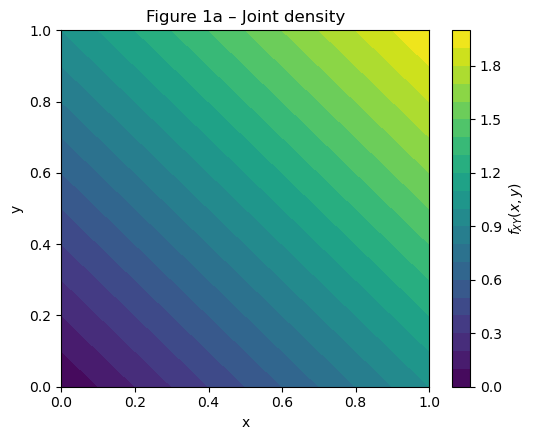

In [17]:
#plot Joint Density
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cont = ax.contourf(Xg, Yg, Zg, levels=20, cmap="viridis")
fig.colorbar(cont, ax=ax, label=r"$f_{XY}(x,y)$")
ax.set(xlabel="x", ylabel="y", title="Figure 1a – Joint density")
plt.tight_layout()
plt.show()

The figure 1a shows joint PDF of X and Y over the unit square where both variables range from 0 to 1 with the denisty increasing linearly in both directions. The lowest density occurs at (0,0) and the highest occurs at (1,1)  with a density of 2. Thus, the intensity becomes hogher toward the upper right corner, which indicates the combination of large values for both variables. Therefore, the joint density shows symmetry across the diagonal x=y with the color intensity representing the value of the joint density.

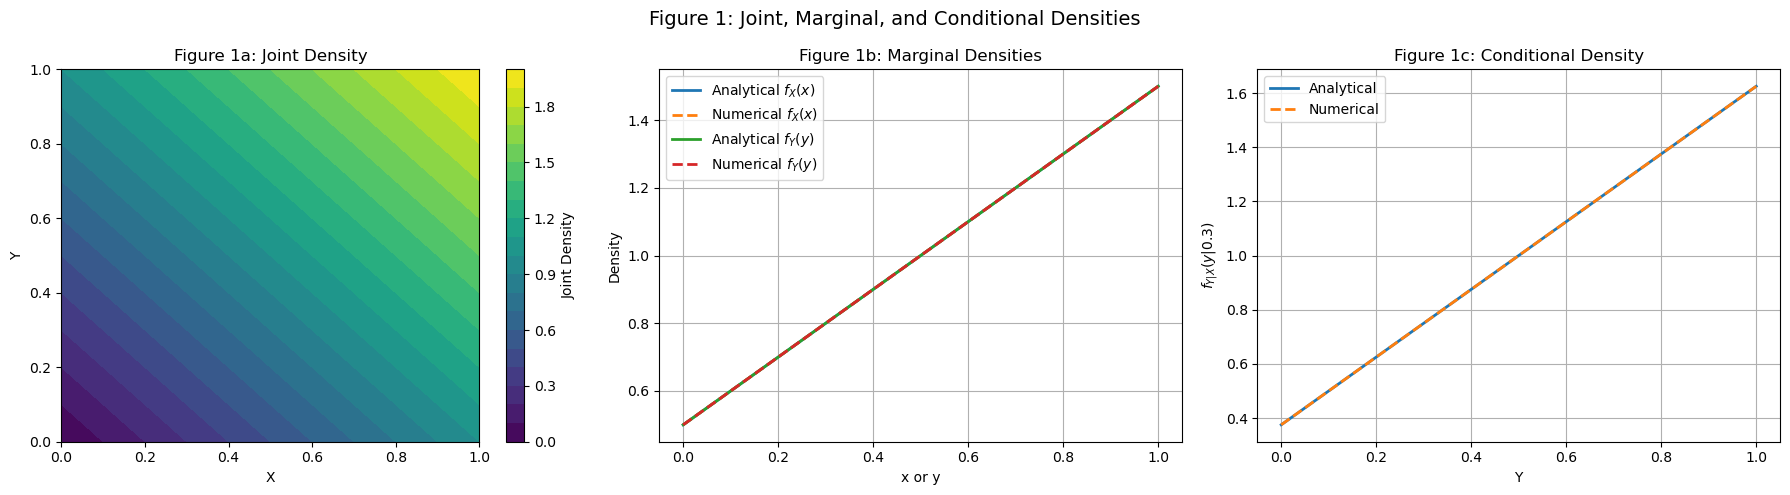

Figure 1 Numerical Verification
--------------------------------
Numerical integral of conditional density: 1.000000
Analytical integral of conditional density: 1.000000
f_X(0.3) analytical: 0.800000
f_X(0.3) numerical: 0.800000


In [18]:
import numpy as np
import matplotlib.pyplot as plt

#STEP 1: FIGURE 1 - THREE PANELS
#Create a grid over the unit square
x = np.linspace(0, 1, 201)
y = np.linspace(0, 1, 201)
X, Y = np.meshgrid(x, y)
#Joint probability density function
f_xy = X + Y
#Numerical marginal densities using trapezoidal integration
#Integrate over y to obtain f_X(x)
f_x_numerical = np.trapezoid(f_xy, y, axis=0)
#Integrate over x to obtain f_Y(y)
f_y_numerical = np.trapezoid(f_xy, x, axis=1)
#Analytical marginal densities
f_x_analytical = x + 0.5
f_y_analytical = y + 0.5

x_given = 0.3
#Analytical conditional density
f_y_given_x = (x_given + y) / (x_given + 0.5)
#Numerical conditional density using numerical marginal
f_y_given_x_numerical = (x_given + y) / np.trapezoid(x_given + y, y)
#Verify conditional density integrates to 1
conditional_integral = np.trapezoid(f_y_given_x, y)

#CREATE THREE-PANEL FIGURE
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#FIGURE 1A: JOINT DENSITY
contour = axes[0].contourf(X, Y, f_xy, levels=20, cmap="viridis")
fig.colorbar(contour, ax=axes[0], label="Joint Density")
axes[0].set_title("Figure 1a: Joint Density")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")

#FIGURE 1B: MARGINALS
#Analytical and numerical marginal of X
axes[1].plot(x, f_x_analytical, label="Analytical $f_X(x)$", linewidth=2)
axes[1].plot(x, f_x_numerical, "--", label="Numerical $f_X(x)$", linewidth=2)

#Analytical and numerical marginal of Y
axes[1].plot(y, f_y_analytical, label="Analytical $f_Y(y)$", linewidth=2)
axes[1].plot(y, f_y_numerical, "--", label="Numerical $f_Y(y)$", linewidth=2)
axes[1].set_title("Figure 1b: Marginal Densities")
axes[1].set_xlabel("x or y")
axes[1].set_ylabel("Density")
axes[1].legend()
axes[1].grid(True)

#FIGURE 1C: CONDITIONAL
axes[2].plot(y, f_y_given_x, label="Analytical", linewidth=2)
axes[2].plot(y, f_y_given_x_numerical, "--", label="Numerical", linewidth=2)
axes[2].set_title("Figure 1c: Conditional Density")
axes[2].set_xlabel("Y")
axes[2].set_ylabel(r"$f_{Y|X}(y|0.3)$")
axes[2].legend()
axes[2].grid(True)

#Overall figure title
fig.suptitle("Figure 1: Joint, Marginal, and Conditional Densities", fontsize=14)
plt.tight_layout()
plt.show()
print("Figure 1 Numerical Verification")
print("--------------------------------")
print(f"Numerical integral of conditional density: "
      f"{conditional_integral:.6f}")
print(f"Analytical integral of conditional density: 1.000000")
print(f"f_X(0.3) analytical: {0.3 + 0.5:.6f}")
print(f"f_X(0.3) numerical: "
      f"{np.interp(0.3, x, f_x_numerical):.6f}")

The following is all plots that were determined before next to each other with some verifications to show that are expected values were correct. Therefore, they show the Joint, Marginal, and Conditional Densities that were calculated and explained before in the previous cells. In the joint density figure, the color intensity represents the joint density, in the marginal density figure, both f_X(x) and f_Y(y) overlap, which indicates their individual similarities, and in the conditional density figure, the density increases linearly from .375 to 1.625 over the interval [0,1] when x = .3. 

The correlation is small and negative, which makes X and Y pull against each other because the joint density f_X,Y(x,y) = x+y increases as either X or Y increases, but gives more weight when one variable is high while the other is low, which is seen in the top right corner of the joint density shape. Therefore, this is expected because the effects of the variables are independent, which causes a weak tendency for the variables to move in opposite directions and a weak negative linear relationship that results in a negative correlation of ρ = -1/11 = -0.0909.

Step 2

Step 3

Step 4

Step 5

Multivariante Gaussian Density

The d-dimensional Gaussian density:

$\ f_X(x) = \frac{1}{(2\pi)^{d/2}|\Sigma|^{1/2}} \exp\left[-\frac12(x-\mu)^T\Sigma^{-1}(x-\mu)\right] \$


$\ d \$ : Dimension of the random vector, which is 2 here.


$\ x \$ : Point where the density is evaluated


$\ \mu : \text{The mean vector which is } \mu = [0,0]^T \$


$$ \Sigma = \begin{bmatrix} 4 & 2 \\ 2 & 4 \end{bmatrix} $$ : This is the covariance matrix.


$\ |\Sigma| \$ : Determinant of the covariance matrix which is 12.


$\ \Sigma^{-1} \$ : The inverse of the covariance matrix.


$\ (x-\mu)^T\Sigma^{-1}(x-\mu) \$ : Squared Mahalanobis distance.


$\ \exp \$ : Exponential function


Therefore,

$$ f_X(x) = \frac{1}{2\pi\sqrt{12}} \exp\left[-\frac12(x-\mu)^T \begin{bmatrix} 1/3 & -1/6 \\ -1/6 & 1/3 \end{bmatrix} (x-\mu)\right] $$

In [19]:
#Generate Density and read contours
#Largest Relative difference at 5 scattered points
mu2 = np.zeros(2)
Sigma2 = np.array([[4.,2.],[2.,4.]])
#five scattered points
points = np.array([[0.2,0.4],[-1.0,0.5],[2.0,-1.5],[3.0,2.0],[-2.5,-0.2]])
#Evaluate using Gaussian PDF
ours = gaussian_pdf(points, mu2, Sigma2)
scipy_pdf = stats.multivariate_normal(mean=mu2, cov=Sigma2).pdf(points)
#Calculate relative difference
relative_diff = np.abs(ours-scipy_pdf)/np.maximum(np.abs(scipy_pdf), 1e-15)
#Display results
print("Our PDF:", ours)
print("SciPy PDF:", scipy_pdf)
print("Largest relative difference:", relative_diff.max())

Our PDF: [0.045034 0.034321 0.009833 0.014307 0.017504]
SciPy PDF: [0.045034 0.034321 0.009833 0.014307 0.017504]
Largest relative difference: 8.820802085403093e-16


The largest difference between using Gaussian PDF function and SciPy PDF for 5 random scattered points was 8.821e-16, which is small enough to assume that both PDFs produce similar values. Thus, the multivariante Gaussian PDF was determined by the determinant of the covariance matrix and a linear system that was calculated using a squared Mahalanobis distance. Therefore, since the largest difference was small, we could assume that both implementations agreed with each other. 

To calculate the Largest Relative Difference we used the equation below:

$\ \text{Largest Relative Difference} = \max_i\left( \frac{|f_{\text{ours}}(x_i) f_{\text{SciPy}}(x_i)|} {|f_{\text{SciPy}}(x_i)|} \right) \$

In [20]:
#Confirm that the density integrates to 1 over large region
integral_2d, integral_err = integrate.dblquad(lambda y, x: float(gaussian_pdf(np.array([x,y]), mu2, Sigma2)), -8, 8, lambda x: -8, lambda x: 8)
print(f"Gaussian PDF integral over [-8,8]^2 = {integral_2d:.10f}")
print(f"Quadrature error estimate = {integral_err:.2e}")

Gaussian PDF integral over [-8,8]^2 = 0.9998742891
Quadrature error estimate = 6.12e-11


Since the Gaussian extends infinitely in every direction, the region that we chose was [-8,8] x [-8,8], which is wide relative to the marginal standard deviation of 2 because both variables have a standard deviation of 2. Thus, my region extends 4 standard deviations in both directions from the mean, 0, which makes the tail probability extremely small. As one can see that the integral over the finite region is close to 1 at a value of 0.9998742891, which has a small missing probability that is due to the far tails. In conclusion, we were able to confirm that the Gaussian density is normalized and that there is only a negligible amount of probability outside the selected region.


Figure 5: Gaussian Probability Contours
Contour     Mahalanobis Radius^2   Density Level      Empirical Fraction    Empirical (%)  
-----------------------------------------------------------------------------------------------
50%         1.386294               0.022972           0.5001                50.01%
90%         4.605170               0.004594           0.9001                90.01%
99%         9.210340               0.000459           0.9895                98.95%

Empirical Probability vs. Theoretical Probability
Contour     Theory        Empirical     Difference      Standard Error    Difference/SE  
-------------------------------------------------------------------------------------
50%         0.5000          0.5001          +0.0001            0.00500             0.020
90%         0.9000          0.9001          +0.0001            0.00300             0.033
99%         0.9900          0.9895          -0.0005            0.00099             0.503
Correlation coefficient:
rho

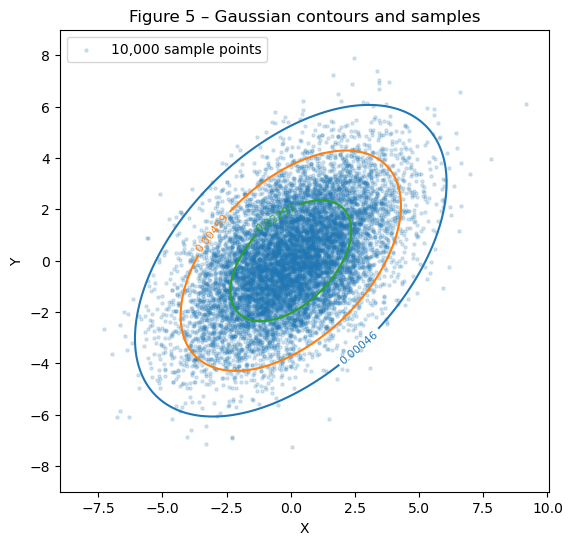

In [21]:
#Plot constant density contours over a scatter with 10^4 samples
N5 = 10_000
s5 = rng_step5.multivariate_normal(mu2, Sigma2, size=N5)
#mark enclosed 50%, 90%, and 99% of probability using chi squared distribution
chi2_levels = stats.chi2.ppf([0.50,0.90,0.99], df=2)
#convert the squared Mahalanobis distance into probability density contour levels
density_levels = np.exp(-0.5*(2*np.log(2*np.pi)+np.linalg.slogdet(Sigma2)[1] +chi2_levels))
invS = np.linalg.solve(Sigma2, np.eye(2))
delta5 = s5-mu2
mahal5 = np.einsum("ni,ij,nj->n", delta5, invS, delta5)
#count the fraction of samples inside
empirical_inside = [(mahal5 <= q).mean() for q in chi2_levels]
contour_percentages = [50, 90, 99]
print("\nFigure 5: Gaussian Probability Contours")
print("=" * 95)
print(f"{'Contour':<12}"
    f"{'Mahalanobis Radius^2':<23}"
    f"{'Density Level':<19}"
    f"{'Empirical Fraction':<22}"
    f"{'Empirical (%)':<15}")
print("-" * 95)
for i, percentage in enumerate(contour_percentages):
    print(f"{percentage}%{'':<9}"
        f"{chi2_levels[i]:<23.6f}"
        f"{density_levels[i]:<19.6f}"
        f"{empirical_inside[i]:<22.4f}"
        f"{empirical_inside[i]*100:.2f}%")
print("=" * 95)

#Standard error comparison
theoretical_inside = np.array([0.50, 0.90, 0.99])
empirical_inside = np.array(empirical_inside)
se_inside = np.sqrt(theoretical_inside * (1 - theoretical_inside) / N5)
differences = empirical_inside - theoretical_inside
difference_in_se = np.abs(differences) / se_inside
print("\nEmpirical Probability vs. Theoretical Probability")
print("=" * 85)
print(f"{'Contour':<12}{'Theory':<14}{'Empirical':<14}"
      f"{'Difference':<16}{'Standard Error':<18}{'Difference/SE':<15}")
print("-" * 85)
for i, percentage in enumerate(contour_percentages):
    print(f"{percentage}%{'':<9}"
        f"{theoretical_inside[i]:.4f}{'':<10}"
        f"{empirical_inside[i]:.4f}{'':<10}"
        f"{differences[i]:+.4f}{'':<12}"
        f"{se_inside[i]:.5f}{'':<13}"
        f"{difference_in_se[i]:.3f}")
print("=" * 85)

#Calculate correlation coefficient
rho = Sigma2[0, 1] / np.sqrt(Sigma2[0, 0] * Sigma2[1, 1])
#Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(Sigma2)
#Sort eigenvalues from largest to smallest
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]
print("Correlation coefficient:")
print(f"rho = {rho:.4f}")
print("\nEllipse axis information:")
for i in range(2):
    direction = eigenvectors[:, i]
    angle = np.degrees(np.arctan2(direction[1], direction[0]))
    print(f"\nAxis {i+1}:")
    print(f"Eigenvalue = {eigenvalues[i]:.4f}")
    print(f"Eigenvector = {direction}")
    print(f"Direction = {angle:.2f} degrees")
    print(f"One-standard-deviation semiaxis = {np.sqrt(eigenvalues[i]):.4f}")

#Calculate ellipse semiaxis lengths for each contour
print("\nContour ellipse semiaxis lengths:")
for probability, q in zip([50, 90, 99], chi2_levels):
    major = np.sqrt(eigenvalues[0] * q)
    minor = np.sqrt(eigenvalues[1] * q)
    print(f"{probability}% contour:")
    print(f"Major semiaxis = {major:.4f}")
    print(f"Minor semiaxis = {minor:.4f}")

xx = np.linspace(-9,9,240)
yy = np.linspace(-9,9,240)
XX, YY = np.meshgrid(xx, yy)
gridpts = np.column_stack([XX.ravel(), YY.ravel()])
pdf_grid = gaussian_pdf(gridpts, mu2, Sigma2).reshape(XX.shape)
fig, ax = plt.subplots(figsize=(7,6))
ax.scatter(s5[:,0], s5[:,1], s=5, alpha=0.18, label="10,000 sample points")
cs = ax.contour(XX, YY, pdf_grid, levels=np.sort(density_levels), colors=["C0","C1","C2"])
ax.clabel(cs, inline=True, fontsize=8)
ax.set(xlabel="X", ylabel="Y", title="Figure 5 – Gaussian contours and samples")
ax.set_aspect("equal", adjustable="box")
ax.legend()
plt.show()

The plot of Figure 5 is the Gaussian contours and 10^4 samples with the contours that enclose 50%, 90%, and 99% of the probability. Thus, at 50%, the density level is .02298, which is indicated with the green line, at 90%, the density level is .0046, which is indicated with the orange line, and at 99%, the density level is .00046, which is indicated with the blue line. Therefore, as the contour for the distribution increases, the density level decreases. Although we notice a decrease in the density, as the contour increases, the Mahalanobis radii squared value increases as well. Thus, the Mahalanobis radii squared value is 1.386294 at 50%, 4.605170 at 90%, and 9.210340 at 99%. When verifying the enclosed fractions empirically by counting the samples, we obtain values similar to .5, .9, and .99 with a small standard error of .005 for .5, .003 for .9, and .00099 for .99. Therefore, since the enclosed fractions were similar to the neccessary result, we were able to confirm that the data we recieved for the constant density contour levels was accurate for 10,000 samples in the bivariate Gaussian distribution. To find the contour levels, we used the chi-square distribution with two degrees of freedom because the squared Mahalanobis distance of a bivariate Gaussian random vector follows a chi-square distribution with two degrees of freedom. Afterward, we used the inverse chi-square cumulative distribution function to calculate the Mahalanobis distance thresholds corresponding to 50%, 90%, and 99% probabilities. The thresholds that we obtained were then converted into constant density contour levels using the multivariate Gaussian probability density function. Thus, for two dimensional Gaussian, the Mahalanobis radii squared distance was obtained by using $\ \chi^2_{2}(p) = -2\ln(1-p) \text{ where the contour enclosing probability p is } (x-\mu)^T\Sigma^{-1}(x-\mu) \$. As one can see by the plot above that the contours are ellipses because the covariance matrix stretches the density along different eigenvector directions. In conclusion, since the empirical probabilities were within three standard errors of the theoretical values, we determined that our simulated Guassian 10^4 sample values were accurate.

Derive $\ \rho \text{ and } \Sigma \$

$\ \rho=\frac{\operatorname{Cov}(X,Y)} {\sigma_X\sigma_Y} = \frac{2}{\sqrt{4}\sqrt{4}} = .5 \$

$$ \Sigma = \begin{bmatrix} 4 & 2 \\ 2 & 4 \end{bmatrix} $$

$\ |\Sigma| = 16 - 4 = 12 \$
<br>
<br>
<br>
Ellipse axes lengths and directions 

Eigenvalues are 6 and 2 where standard deviation semi axis lengths are 

$\ \sqrt6 = 2.449 \text{ and } \sqrt2 = 1.414 \$

$\ \lambda_1 = 6 \qquad \lambda_2 = 2 \$

Eigenvectors are:

$$ v_1=\frac{1}{\sqrt{2}} \begin{bmatrix}1\\1\end{bmatrix} $$

$$ v_2=\frac{1}{\sqrt{2}} \begin{bmatrix}1\\-1\end{bmatrix} $$

Thus, the directions of the ellipse axes are 45 degrees for the major axis with a standard deviation length of 2.449, which is along y = x, and -45 degrees for the minor axis with standard deviation length of 1.414, which is along y = -x. 


The correlation coefficient which was $\ \rho = .5 \$ was calculated from the covariance matrix, which indicates that the two Gaussian random variables have a positive relationship. The eigenvalues of the covariance matrix are 6 and 2, which correspond to the major and minor ellipse axes. Thus, the major axis with a standard deviation length of 2.449 has the direction of 45 degrees, which lies in the y = x, while the minor axis with a standard deviation length of 1.414 has the direction of -45 degrees or 135 degrees, which lies in the y = -x. In conclusion, the ellipse is stretched along the positive diagonal and the semiaxis lengths for the 50%, 90%, and 99% contours were calculated by multiplying the square roots of the eigenvalues by the square root of the corresponding chi-square threshold.

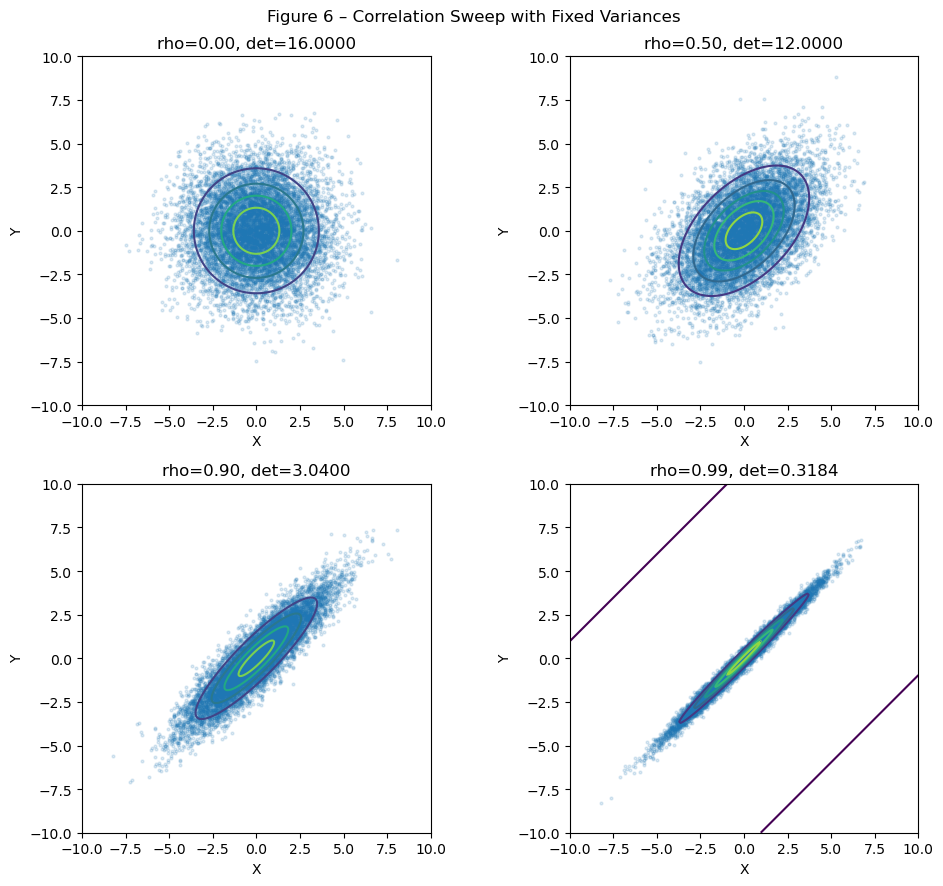

In [22]:
#contour plot for 𝜌 = 0, 𝜌 = 0.5, 𝜌 = 0.9 and 𝜌 = 0.99
#Figure 6: Contour plots for different correlations
rhos = [0.0, 0.5, 0.9, 0.99]
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
u = np.linspace(-10, 10, 240)
U, V = np.meshgrid(u, u)
for ax, rho in zip(axes.ravel(), rhos):
    S = np.array([[4., 4*rho], [4*rho, 4.]])
    #Generate 10,000 samples for each correlation
    sample = rng_step5.multivariate_normal([0, 0], S, size=10_000)
    pgrid = gaussian_pdf(np.column_stack([U.ravel(), V.ravel()]), np.zeros(2), S).reshape(U.shape)
    #Display all 10,000 samples
    ax.scatter(sample[:, 0], sample[:, 1], s=4, alpha=0.15)
    ax.contour(U, V, pgrid, levels=5)
    ax.set_title(f"rho={rho:.2f}, det={np.linalg.det(S):.4f}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_aspect("equal", adjustable="box")
fig.suptitle("Figure 6 – Correlation Sweep with Fixed Variances")
plt.tight_layout()
plt.show()

In figure 6, one can see that the correlation coefficient increases from 0 to .99, while the Gaussian probability contours become stretched along the positive diagonal and narrow in the perpendicular direction. Thus, the determinant of the covariance matrix decreases from 16 to .3184, which means that it approaches 0 as the correlation coefficient approaches 1. Therefore, this indicates that the two measurements are becoming increasingly dependent and contain more overlapping information. After all, when the correlation coefficient reaches 1, then the covariance matrix becomes singular, which indicates that the second measurement provides no additional independent information other than what was included in the first measurement. In conclusion, since the two measurements are correlated with equal variances and zero means, knowing the first measurement will provide a great indication for the second measurement.

Formula for calculating determinant:

$\ {|\Sigma|=16(1-\rho^2)} \$

Step 6

Step 7

Step 8

The quantity $\ S \sim N(0,4) \$ is measured by two sensors: 

$\ X_1 = S + N_1,\qquad X_2 = S + N_2 \$

The Noise vector is zero mean: 

$\ N = \mathbf1=[N_1,N_2]^T \$

where:

$$ \Sigma_N = \begin{bmatrix} 1&c \\ c&2 \end{bmatrix} $$

Sensor 2 is also noiser than sensor 1, while the c parameter controls how correlated the noise is.

Derivation for $\ \Sigma_{xx} \text{ and } \Sigma_{sx} \text{ in terms of } \sigma_S^2 \text{ and } \Sigma_N \$ :

$\ \mathbf x = [X_1,X_2]^T \text{ therefore, } \mathbf1 = [1,1]^T \text{ and } \sigma_S^2 = 4 \$


After all, $\ \mathbf x = \mathbf1S + \mathbf N \$






$\ \Sigma_{xx} = E[\mathbf x\mathbf x^T] \$

$\ E[\mathbf x\mathbf x^T] = \sigma_S^2 [1,1] + \Sigma_N \$

$\ \sigma_S^2 [1,1] + \Sigma_N = 4 + \Sigma_N \$

= $$ \Sigma_N = \begin{bmatrix} 1 + 4 & c + 4 \\ c + 4 & 2 + 4 \end{bmatrix} $$

= $$ \begin{bmatrix} 5 & 4+c \\ 4+c & 6 \end{bmatrix} $$

$\ \Sigma_{xx} = \$ 

$$ \begin{bmatrix} 5 & 4+c \\ 4+c & 6 \end{bmatrix} $$

$\ \Sigma_{sx}=E[S\mathbf x^T] = \sigma_S^2[1,1] = 4[1,1] = [4,4] \$

The linear MMSE estimator $$ \hat S = \mathbf w^T \mathbf x \text{ has } \mathbf w = \Sigma_{xx}^{-1} \Sigma_{xs} $$ to minimize the mean square error. 

The resulting MMSE is:

$$ \operatorname{MMSE} = \sigma_S^2 - \Sigma_{sx} \Sigma_{xx}^{-1} \Sigma_{xs} $$

$$ E[S]=0,\qquad \sigma_S^2=\operatorname{Var}(S)=4 $$

The optimal weight vector is calculated using

$$ \mathbf w = \Sigma_{XX}^{-1} \Sigma_{XS} $$

$$ \Sigma_{XS} = \Sigma_{SX}^T $$

$$ \mathbf w = \begin{bmatrix} 5 & 4+c \\ 4+c & 6 \end{bmatrix}^{-1} \begin{bmatrix} 4 \ 4 \end{bmatrix} $$

$$ \mathbf w= \frac{1}{30-(4+c)^2} \begin{bmatrix} 6 & -(4+c)\\ -(4+c) & 5 \end{bmatrix} \begin{bmatrix} 4 \\ 4 \end{bmatrix} $$

Thus, the two optimal weights are

$$ {w_1 = \frac{4(2-c)}{30-(4+c)^2}} $$

$$ {w_2=\frac{4(1-c)}{30-(4+c)^2}} $$

when c=1 $$ {w_2=\frac{4(1-c)}{30-(4+c)^2}} $$ is equal to 0 and negative beyond 1.

$$ \hat S = w_1X_1 + w_2X_2 $$
<br>
<br>
<br>
The minimum mean-square error is

$$ \sigma_S^2 - \Sigma_{SX} \Sigma_{XX}^{-1} \Sigma_{XS} $$

Substitute the known values:

$$ \text{MMSE} = 4 - \begin{bmatrix} 4 & 4 \end{bmatrix} \begin{bmatrix} 5 & 4+c \\ 4+c & 6 \end{bmatrix}^{-1} \begin{bmatrix} 4 \\ 4 \end{bmatrix} $$

$\ \operatorname{MMSE}(c) = \frac{4(2-c^2)}{14-8c-c^2} \$


The noise covariance is Positive Semi-Definite when the diagonal entries are non-negative and the determinant is non-negative. Thus, Σ𝑁 is a valid covariance when it is PSD.

Thus,

$\ 2-c^2 \geq 0 \$

$$ |c|\leq\sqrt2 $$

It is positive definite when:

$$|c| < \sqrt2 $$

In conclusion, Σ𝑁 is valid when $$|c| < \sqrt2 = .41421 $$ and at the endpoints it is also singular.

when $$|c| < \sqrt1 $$

$\ \operatorname{MMSE}(1) = \frac{4(2-1^2)}{14-8c-1^2} = 4/5 \$

Thus, since the diagonal entries are non negative and the determinant is non-negative, Σ𝑁 is a valid covariance matrix.


In [24]:
#Tabulate 𝑤1, 𝑤2 and the MMSE at different c values
sigma_s2 = 4.0
def step8_matrices(c):
    SigmaN = np.array([[1.,c],[c,2.]])
    one = np.ones(2)
    Sxx = sigma_s2*np.outer(one,one)+SigmaN
    Ssx = sigma_s2*one
    return SigmaN,Sxx,Ssx
def step8_theory(c):
    _,Sxx,Ssx=step8_matrices(c)
    w=lmmse_weights(Sxx,Ssx)
    mse=sigma_s2-Ssx@w
    return w,mse
c_values=np.array([-1.4,-1.0,-0.5,0.0,0.5,1.0,1.2,1.4])
best_single= sigma_s2*1/(sigma_s2+1) #sensor 1 noise variance is 1
table=[]
for cval in c_values:
    w,mse=step8_theory(cval)
    equal_mse=(3+2*cval)/4
    table.append((cval,w[0],w[1],mse,best_single,equal_mse))
print("c       w1        w2        MMSE       sensor1-only   equal weights")
for row in table:
    print(f"{row[0]:5.1f}  {row[1]:8.5f}  {row[2]:8.5f}  {row[3]:9.6f}  " f"{row[4]:9.6f}      {row[5]:9.6f}")

c       w1        w2        MMSE       sensor1-only   equal weights
 -1.4   0.58520   0.41308   0.006885   0.800000       0.050000
 -1.0   0.57143   0.38095   0.190476   0.800000       0.250000
 -0.5   0.56338   0.33803   0.394366   0.800000       0.500000
  0.0   0.57143   0.28571   0.571429   0.800000       0.750000
  0.5   0.61538   0.20513   0.717949   0.800000       1.000000
  1.0   0.80000   0.00000   0.800000   0.800000       1.250000
  1.2   1.08108  -0.27027   0.756757   0.800000       1.350000
  1.4   2.85714  -1.90476   0.190476   0.800000       1.450000


After comparing each result against the best single sensor and naive equal weighting we noticed that the best single sensor appears at c = 1, because the best single sensor produces a result of .8, which appears throughout the chart.

At c = 1, the estimator ignores sensor 2 and uses only sensor 1, that produces a value of .8. Thus, the denominator 14 - 8c - c^2 is positive throughout the interval, which produces a value of 1-c is equal to the sign of w2. Therefore, when c<1 w2>0, when c=1 w2=1, and when c>1 w2<0.

$$ {w_2=\frac{4(1-c)}{30-(4+c)^2}} $$

c=1:

$$ {w_2=\frac{4(1-1)}{30-(4+1)^2}} $$

$$ w_2 = 0 $$

$$ {w_1 = \frac{4(2-c)}{30-(4+c)^2}} $$

$$ {w_1 = \frac{4(2-1)}{30-(4+1)^2}} $$

$$ {w_1 = \frac{4}{30-(5)^2}} $$

$$ {w_1 = \frac{4}{5}} $$

$$ w_1 = .8 $$

$\ \operatorname{MMSE}(c) = \frac{4(2-c^2)}{14-8c-c^2} \$

$\ \operatorname{MMSE}(1) = \frac{4(2-1^2)}{14-8(1)-1^2} \$

$\ \operatorname{MMSE}(1) = \frac{4}{14-8-1} \$

$\ \operatorname{MMSE}(1) = \frac{4}{5} \$

$\ \operatorname{MMSE}(1) = .8 \$


Proof of stationary point:

$\ \frac{d}{dc}\operatorname{MMSE}(c) = \frac{32(c-2)(c-1)}{(c^2+8c-14)^2} \$

Thus, when c=1 is stationary because the derivative of MMSE is 0 at c=1. Since the second derivative is -32/25 at c = 1, which is less than 0, the stationary point is a local max not a min. After all, the other root of c = 2 is outside the admissible range.

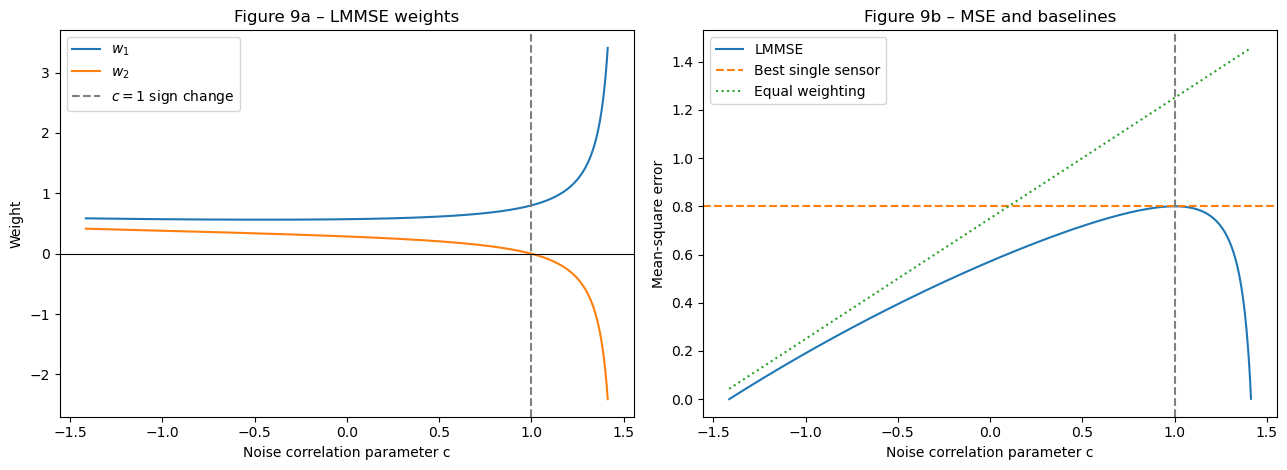

In [25]:
#plot figure 9 for different c values
cplot=np.linspace(-np.sqrt(2)+1e-4,np.sqrt(2)-1e-4,600)
weights_plot=np.array([step8_theory(cv)[0] for cv in cplot])
mse_plot=np.array([step8_theory(cv)[1] for cv in cplot])
equal_plot=(3+2*cplot)/4
fig,ax=plt.subplots(1,2,figsize=(13,4.8))
ax[0].plot(cplot,weights_plot[:,0],label="$w_1$")
ax[0].plot(cplot,weights_plot[:,1],label="$w_2$")
ax[0].axhline(0,color="black",linewidth=.8)
ax[0].axvline(1,color="gray",linestyle="--",label="$c=1$ sign change")
ax[0].set(xlabel="Noise correlation parameter c",ylabel="Weight", title="Figure 9a – LMMSE weights")
ax[0].legend()
ax[1].plot(cplot,mse_plot,label="LMMSE")
ax[1].axhline(best_single,color="C1",linestyle="--",label="Best single sensor")
ax[1].plot(cplot,equal_plot,color="C2",linestyle=":",label="Equal weighting")
ax[1].axvline(1,color="gray",linestyle="--")
ax[1].set(xlabel="Noise correlation parameter c",ylabel="Mean-square error", title="Figure 9b – MSE and baselines")
ax[1].legend()
plt.tight_layout()
plt.show()

Figure 9 above 